# Business Problem


"""A bank processes a large volume of financial transactions across multiple channels, including mobile applications, ATMs, websites, APIs, and branches. The bank needs better visibility into transaction performance, failed transactions, potential fraudulent activity, customer credit profiles, and loan-related indicators.

Currently, the bank faces challenges in identifying unusual transaction patterns, monitoring transaction failures, understanding channel performance, and analyzing risk indicators such as KYC status, credit scores, and loan obligations.

The objective of this project is to analyze banking transaction data using Python and Power BI to identify transaction trends, monitor potential fraud indicators, evaluate channel performance, and generate actionable insights that support operational efficiency and risk monitoring."""

In [319]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Importing the dataset

In [321]:
df=pd.read_csv(r"C:\Users\USER\Downloads\indian_banking_transactions.csv")

In [322]:
df.head(5)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


In [323]:
print("number of columns and rows",df.shape)

number of columns and rows (550000, 20)


In [324]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         550000 non-null  object 
 1   customer_id            550000 non-null  object 
 2   transaction_date       550000 non-null  object 
 3   transaction_time       550000 non-null  object 
 4   account_type           550000 non-null  object 
 5   transaction_type       550000 non-null  object 
 6   transaction_amount     550000 non-null  float64
 7   transaction_direction  550000 non-null  object 
 8   account_balance        550000 non-null  float64
 9   merchant_category      550000 non-null  object 
 10  state                  550000 non-null  object 
 11  credit_score           550000 non-null  int64  
 12  has_loan               550000 non-null  int64  
 13  loan_type              172866 non-null  object 
 14  emi_amount             550000 non-nu

In [325]:
pd.set_option('display.float_format', '{:.2f}'.format)

df.describe()

,transaction_amount,account_balance,credit_score,has_loan,emi_amount,is_fraud,transaction_hour
count,550000.00,550000.00,550000.00,550000.00,550000.00,550000.00,550000.00
mean,29907.09,84550.12,599.81,0.35,2365.86,0.01,11.50
std,139610.10,170914.59,173.05,0.48,4973.55,0.09,6.92
min,2.40,500.00,300.00,0.00,0.00,0.00,0.00
25%,763.04,15157.78,450.00,0.00,0.00,0.00,6.00
50%,2035.74,36422.87,600.00,0.00,0.00,0.00,11.00
75%,8557.50,87607.04,750.00,1.00,3115.03,0.00,17.00
max,10000000.00,5000000.00,899.00,1.00,153325.74,1.00,23.00


In [326]:
df.columns=df.columns.str.strip()

# Data Cleaning

In [328]:
df.duplicated().sum()

0

In [329]:
df["transaction_id"].unique()

array(['TXN000000001', 'TXN000000002', 'TXN000000003', ...,
       'TXN000549998', 'TXN000549999', 'TXN000550000'], dtype=object)

In [330]:
df["transaction_id"].nunique()

550000

In [331]:
df["transaction_id"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 550000 entries, 0 to 549999
Series name: transaction_id
Non-Null Count   Dtype 
--------------   ----- 
550000 non-null  object
dtypes: object(1)
memory usage: 4.2+ MB


------------------------------

In [333]:
df["customer_id"].unique()

array(['CUST015796', 'CUST000861', 'CUST076821', ..., 'CUST058012',
       'CUST021749', 'CUST058427'], dtype=object)

In [334]:
df["customer_id"].nunique()

79916

In [335]:
df["customer_id"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 550000 entries, 0 to 549999
Series name: customer_id
Non-Null Count   Dtype 
--------------   ----- 
550000 non-null  object
dtypes: object(1)
memory usage: 4.2+ MB


-----------------------------

In [337]:
print(df["transaction_date"].unique().tolist())

['2019-01-01', '2019-01-02', '2019-01-03', '2019-01-04', '2019-01-05', '2019-01-06', '2019-01-07', '2019-01-08', '2019-01-09', '2019-01-10', '2019-01-11', '2019-01-12', '2019-01-13', '2019-01-14', '2019-01-15', '2019-01-16', '2019-01-17', '2019-01-18', '2019-01-19', '2019-01-20', '2019-01-21', '2019-01-22', '2019-01-23', '2019-01-24', '2019-01-25', '2019-01-26', '2019-01-27', '2019-01-28', '2019-01-29', '2019-01-30', '2019-01-31', '2019-02-01', '2019-02-02', '2019-02-03', '2019-02-04', '2019-02-05', '2019-02-06', '2019-02-07', '2019-02-08', '2019-02-09', '2019-02-10', '2019-02-11', '2019-02-12', '2019-02-13', '2019-02-14', '2019-02-15', '2019-02-16', '2019-02-17', '2019-02-18', '2019-02-19', '2019-02-20', '2019-02-21', '2019-02-22', '2019-02-23', '2019-02-24', '2019-02-25', '2019-02-26', '2019-02-27', '2019-02-28', '2019-03-01', '2019-03-02', '2019-03-03', '2019-03-04', '2019-03-05', '2019-03-06', '2019-03-07', '2019-03-08', '2019-03-09', '2019-03-10', '2019-03-11', '2019-03-12', '2019

In [338]:
df["transaction_date"].nunique()

1827

In [339]:
df["transaction_date"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 550000 entries, 0 to 549999
Series name: transaction_date
Non-Null Count   Dtype 
--------------   ----- 
550000 non-null  object
dtypes: object(1)
memory usage: 4.2+ MB


In [340]:
df["transaction_date"].describe

<bound method NDFrame.describe of 0         2019-01-01
1         2019-01-01
2         2019-01-01
3         2019-01-01
4         2019-01-01
             ...    
549995    2024-01-01
549996    2024-01-01
549997    2024-01-01
549998    2024-01-01
549999    2024-01-01
Name: transaction_date, Length: 550000, dtype: object>

---------------------

In [342]:
df.head(2)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3


In [343]:
df["transaction_time"].unique()

array(['15:28', '03:00', '18:03', ..., '23:41', '16:38', '15:12'],
      dtype=object)

In [344]:
df["transaction_time"].nunique()

1440

In [345]:
df["transaction_time"].describe()

count     550000
unique      1440
top        06:25
freq         448
Name: transaction_time, dtype: object

In [346]:
df["transaction_time"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 550000 entries, 0 to 549999
Series name: transaction_time
Non-Null Count   Dtype 
--------------   ----- 
550000 non-null  object
dtypes: object(1)
memory usage: 4.2+ MB


---------------------------------------

In [348]:
df["account_type"].unique()

array(['Current', 'Fixed Deposit', 'Savings', 'Salary', 'NRI'],
      dtype=object)

In [349]:
df["transaction_type"].unique()

array(['UPI', 'POS', 'Net_Banking', 'NEFT', 'Credit_Card', 'Cheque',
       'ATM_Withdrawal', 'IMPS', 'RTGS', 'Auto_Debit'], dtype=object)

In [350]:
df["transaction_amount"].unique()

array([ 1820.17,   392.67,  1255.97, ..., 49230.81, 34250.35,  1653.11])

In [351]:
df["transaction_amount"].describe()

count     550000.00
mean       29907.09
std       139610.10
min            2.40
25%          763.04
50%         2035.74
75%         8557.50
max     10000000.00
Name: transaction_amount, dtype: float64

In [352]:
df[df["transaction_amount"]==10000000.00]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
371877,TXN000371878,CUST053927,2022-05-21,20:13,Current,NEFT,10000000.00,Debit,21776.31,Retail,UP,619,0,NaN,0.00,Success,Mobile_App,Verified,0,20
386302,TXN000386303,CUST061467,2022-07-07,02:27,Current,Cheque,10000000.00,Debit,42180.76,Government,Karnataka,815,1,Auto,12047.36,Success,Mobile_App,Verified,0,2
526796,TXN000526797,CUST038846,2023-10-16,13:23,Salary,Cheque,10000000.00,Debit,80694.61,Food & Dining,Telangana,692,1,Education,3188.15,Success,Web,Verified,0,13
532757,TXN000532758,CUST003107,2023-11-05,10:11,NRI,Cheque,10000000.00,Credit,12230.57,Retail,Delhi,762,1,Business,3172.64,Success,Mobile_App,Verified,0,10


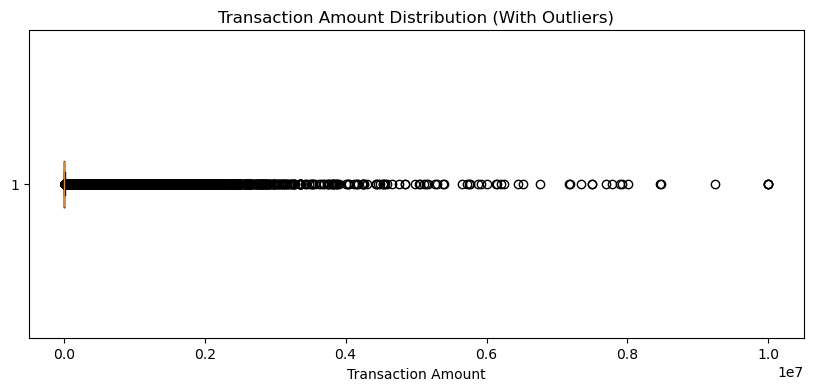

In [353]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df["transaction_amount"].dropna(),
    vert=False,
    showfliers=True
)

plt.title("Transaction Amount Distribution (With Outliers)")
plt.xlabel("Transaction Amount")
plt.show()

In [354]:
amount = df["transaction_amount"].dropna()

Q1 = amount.quantile(0.25)
Q3 = amount.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 763.0374999999999
Q3: 8557.4975
IQR: 7794.459999999999
Lower limit: -10928.652499999998
Upper limit: 20249.1875


In [355]:
outliers = df.loc[
    (df["transaction_amount"] < lower_limit) |
    (df["transaction_amount"] > upper_limit)
]

print("Number of outlier rows:", len(outliers))

print(outliers["transaction_amount"].sort_values(ascending=False))

Number of outlier rows: 88976
526796   10000000.00
532757   10000000.00
386302   10000000.00
371877   10000000.00
432561    9236223.15
             ...    
242694      20253.24
316816      20252.74
455077      20252.14
229430      20252.11
428094      20251.47
Name: transaction_amount, Length: 88976, dtype: float64


-------------------------------------

In [357]:
df["transaction_direction"].unique()

array(['Debit', 'Credit'], dtype=object)

In [358]:
df.head(1)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15


In [359]:
df["account_balance"].unique()

array([609365.31,  14451.14,  47621.87, ...,  83129.91,   8224.44,
         5912.63])

In [360]:
df["account_balance"].describe()

count    550000.00
mean      84550.12
std      170914.59
min         500.00
25%       15157.78
50%       36422.87
75%       87607.04
max     5000000.00
Name: account_balance, dtype: float64

In [361]:
df.sort_values(by="account_balance",ascending=False).head(5)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
353488,TXN000353489,CUST042527,2022-03-20,07:19,NRI,ATM_Withdrawal,1000.00,Debit,5000000.00,Salary,Telangana,618,0,NaN,0.00,Success,Mobile_App,Verified,0,7
239009,TXN000239010,CUST042968,2021-03-05,16:24,NRI,POS,629.78,Debit,5000000.00,Salary,Gujarat,323,0,NaN,0.00,Success,Mobile_App,Verified,0,16
536911,TXN000536912,CUST066518,2023-11-19,10:08,Current,IMPS,1941.29,Credit,5000000.00,Food & Dining,Maharashtra,695,1,Education,903.45,Success,API,Verified,0,10
459575,TXN000459576,CUST067546,2023-03-07,07:24,Savings,RTGS,328985.61,Credit,5000000.00,Entertainment,Maharashtra,705,0,NaN,0.00,Success,Branch,Verified,0,7
137981,TXN000137982,CUST076816,2020-04-03,20:10,Current,Credit_Card,1006.71,Debit,5000000.00,Retail,Telangana,443,0,NaN,0.00,Success,Mobile_App,Verified,0,20


In [362]:
df.loc[
    (df["transaction_type"] == "RTGS") &
    (df["transaction_amount"] < 200000),
    ["transaction_type","transaction_date", "transaction_amount",
     "transaction_direction", "account_balance"]
].head(5)

,transaction_type,transaction_date,transaction_amount,transaction_direction,account_balance
20,RTGS,2019-01-01,24601.60,Debit,25884.35
21,RTGS,2019-01-01,73416.02,Credit,21042.96
54,RTGS,2019-01-01,28438.49,Credit,34822.82
68,RTGS,2019-01-01,79938.63,Debit,199447.61
130,RTGS,2019-01-01,127915.93,Credit,3925.47


In [363]:
df.head(1)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15


In [364]:
df[df["transaction_type"]=="RTGS"]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
20,TXN000000021,CUST071933,2019-01-01,18:37,Current,RTGS,24601.60,Debit,25884.35,E-Commerce,UP,890,1,Gold,9645.10,Success,Web,Verified,0,18
21,TXN000000022,CUST025659,2019-01-01,05:29,Current,RTGS,73416.02,Credit,21042.96,Travel,Rajasthan,862,0,NaN,0.00,Success,Mobile_App,Verified,0,5
54,TXN000000055,CUST009693,2019-01-01,18:28,Salary,RTGS,28438.49,Credit,34822.82,Salary,West Bengal,789,0,NaN,0.00,Success,Mobile_App,Verified,0,18
68,TXN000000069,CUST009269,2019-01-01,19:00,Current,RTGS,79938.63,Debit,199447.61,Utilities,UP,352,1,NaN,5683.47,Success,ATM,Pending,0,19
91,TXN000000092,CUST026855,2019-01-01,05:24,Salary,RTGS,217578.55,Credit,16619.09,Education,Delhi,595,0,NaN,0.00,Success,POS_Terminal,Verified,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549942,TXN000549943,CUST007632,2024-01-01,22:57,Savings,RTGS,27787.13,Debit,15460.12,Salary,Telangana,468,0,NaN,0.00,Success,Mobile_App,Verified,0,22
549958,TXN000549959,CUST052373,2024-01-01,23:13,Salary,RTGS,336945.30,Debit,7935.31,Salary,Rajasthan,568,1,Personal,12084.87,Success,ATM,Verified,0,23
549960,TXN000549961,CUST044113,2024-01-01,04:36,Savings,RTGS,46067.85,Debit,55835.37,Healthcare,Maharashtra,503,0,NaN,0.00,Success,Mobile_App,Verified,0,4
549986,TXN000549987,CUST065930,2024-01-01,09:01,Savings,RTGS,53861.67,Debit,21126.61,Retail,Rajasthan,707,1,Personal,3977.68,Success,Web,Verified,0,9


In [365]:
df

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549995,TXN000549996,CUST058822,2024-01-01,21:46,Savings,UPI,1961.49,Debit,21701.27,Education,Maharashtra,503,0,NaN,0.00,Success,POS_Terminal,Expired,0,21
549996,TXN000549997,CUST033092,2024-01-01,17:19,Savings,Credit_Card,478.53,Debit,28358.13,Entertainment,Gujarat,509,1,Home,15013.47,Success,Mobile_App,Verified,0,17
549997,TXN000549998,CUST027778,2024-01-01,23:23,Current,NEFT,49230.81,Credit,83129.91,Government,Telangana,878,0,NaN,0.00,Success,ATM,Verified,0,23
549998,TXN000549999,CUST011271,2024-01-01,12:31,Current,NEFT,34250.35,Credit,8224.44,Peer Transfer,Delhi,598,1,Personal,3093.37,Success,Branch,Verified,0,12


In [366]:
df["data_quality_flag"] = "Valid"

mask = (
    (df["transaction_type"] == "RTGS") &
    (df["transaction_amount"] < 200000)
)

df.loc[mask, "data_quality_flag"] = "Review Required"

In [367]:
data_quality_check=df[df["data_quality_flag"]=="Review Required"]

--------------------------------

In [369]:
df["account_balance"].describe()

count    550000.00
mean      84550.12
std      170914.59
min         500.00
25%       15157.78
50%       36422.87
75%       87607.04
max     5000000.00
Name: account_balance, dtype: float64

In [370]:

   df[ (df["transaction_type"] == "UPI") &
    (df["transaction_amount"] > 100000)]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
141988,TXN000141989,CUST054233,2020-04-16,01:37,Salary,UPI,118082.51,Credit,7798.67,Government,...,857,1,Home,2736.38,Success,Web,Verified,0,1,Valid


In [371]:
df["merchant_category"].unique()

array(['Food & Dining', 'Education', 'Utilities', 'Travel', 'Government',
       'Investment', 'Healthcare', 'Real Estate', 'E-Commerce', 'Retail',
       'Fuel', 'Salary', 'Entertainment', 'Peer Transfer', 'Insurance'],
      dtype=object)

In [372]:
df["state"].unique()

array(['Maharashtra', 'West Bengal', 'Punjab', 'Karnataka', 'Tamil Nadu',
       'Telangana', 'Delhi', 'UP', 'Rajasthan', 'Gujarat'], dtype=object)

In [373]:
df["credit_score"].unique()

array([764, 630, 813, 628, 767, 707, 361, 651, 443, 330, 358, 500, 452,
       843, 511, 794, 525, 888, 582, 614, 890, 862, 517, 347, 834, 738,
       376, 770, 481, 667, 653, 721, 655, 785, 316, 372, 484, 649, 512,
       633, 678, 894, 366, 779, 835, 504, 867, 491, 860, 617, 609, 670,
       533, 789, 711, 576, 885, 757, 338, 456, 811, 664, 804, 774, 642,
       681, 352, 319, 626, 478, 634, 422, 579, 850, 864, 312, 351, 883,
       661, 587, 695, 847, 573, 739, 846, 812, 749, 595, 817, 325, 483,
       326, 615, 368, 672, 858, 397, 881, 799, 870, 842, 336, 627, 841,
       647, 385, 407, 611, 616, 638, 301, 340, 665, 796, 810, 558, 570,
       459, 508, 815, 897, 666, 752, 745, 493, 571, 414, 852, 710, 590,
       572, 874, 830, 417, 606, 703, 364, 838, 589, 432, 401, 542, 408,
       454, 807, 334, 509, 832, 623, 825, 563, 641, 859, 490, 457, 691,
       398, 632, 343, 797, 436, 302, 803, 692, 682, 355, 530, 391, 720,
       513, 532, 495, 750, 441, 612, 671, 660, 731, 418, 472, 47

In [374]:
df["credit_score"].nunique()

600

In [375]:
df["credit_score"].describe()

count   550000.00
mean       599.81
std        173.05
min        300.00
25%        450.00
50%        600.00
75%        750.00
max        899.00
Name: credit_score, dtype: float64

In [376]:
df["has_loan"].unique()

array([0, 1], dtype=int64)

In [377]:
df["has_loan"].isnull().sum()

0

In [378]:
df["loan_type"].unique()

array([nan, 'Home', 'Personal', 'Auto', 'Gold', 'Education', 'Business'],
      dtype=object)

In [379]:
df[df["loan_type"].isnull()]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,...,764,0,NaN,0.00,Success,Branch,Verified,0,15,Valid
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,...,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3,Valid
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,...,767,0,NaN,0.00,Success,API,Verified,0,14,Valid
7,TXN000000008,CUST060264,2019-01-01,23:40,Current,Net_Banking,17797.85,Debit,17568.23,Healthcare,...,651,0,NaN,0.00,Success,Mobile_App,Expired,0,23,Valid
8,TXN000000009,CUST016024,2019-01-01,20:25,Salary,Credit_Card,3284.62,Debit,66973.00,Food & Dining,...,443,0,NaN,0.00,Success,Web,Verified,0,20,Valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549993,TXN000549994,CUST071025,2024-01-01,19:45,Fixed Deposit,RTGS,20460.38,Debit,182248.69,Entertainment,...,673,0,NaN,0.00,Success,Mobile_App,Verified,0,19,Review Required
549994,TXN000549995,CUST066266,2024-01-01,11:00,Salary,UPI,794.03,Debit,65584.16,Retail,...,611,0,NaN,0.00,Success,Mobile_App,Verified,0,11,Valid
549995,TXN000549996,CUST058822,2024-01-01,21:46,Savings,UPI,1961.49,Debit,21701.27,Education,...,503,0,NaN,0.00,Success,POS_Terminal,Expired,0,21,Valid
549997,TXN000549998,CUST027778,2024-01-01,23:23,Current,NEFT,49230.81,Credit,83129.91,Government,...,878,0,NaN,0.00,Success,ATM,Verified,0,23,Valid


In [380]:
df.loc[df["has_loan"] == 0, "loan_type"] = (
    df.loc[df["has_loan"] == 0, "loan_type"]
    .fillna("No Loan")
)

df.loc[df["has_loan"] == 1, "loan_type"] = (
    df.loc[df["has_loan"] == 1, "loan_type"]
    .fillna("Unknown")
)

In [381]:
df[df["loan_type"]=="Unknown"]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
40,TXN000000041,CUST023898,2019-01-01,11:35,Savings,Auto_Debit,879.10,Debit,45807.46,E-Commerce,...,633,1,Unknown,8597.49,Success,Web,Verified,0,11,Valid
41,TXN000000042,CUST068149,2019-01-01,20:07,Salary,UPI,634.61,Credit,232027.81,Peer Transfer,...,678,1,Unknown,6697.80,Success,API,Verified,0,20,Valid
68,TXN000000069,CUST009269,2019-01-01,19:00,Current,RTGS,79938.63,Debit,199447.61,Utilities,...,352,1,Unknown,5683.47,Success,ATM,Pending,0,19,Review Required
72,TXN000000073,CUST008572,2019-01-01,07:12,Savings,UPI,424.06,Debit,706365.16,E-Commerce,...,478,1,Unknown,8317.18,Success,API,Verified,0,7,Valid
109,TXN000000110,CUST052993,2019-01-01,14:02,Current,Credit_Card,834.03,Debit,66941.13,E-Commerce,...,841,1,Unknown,6982.45,Success,ATM,Verified,0,14,Valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549871,TXN000549872,CUST062548,2024-01-01,14:10,Salary,POS,1702.72,Debit,114006.16,Education,...,395,1,Unknown,2028.05,Success,Mobile_App,Verified,0,14,Valid
549879,TXN000549880,CUST001080,2024-01-01,03:18,Current,UPI,461.13,Credit,14633.47,Retail,...,338,1,Unknown,6953.50,Success,Mobile_App,Verified,0,3,Valid
549889,TXN000549890,CUST065835,2024-01-01,23:31,Savings,IMPS,806.65,Credit,71125.87,E-Commerce,...,571,1,Unknown,4998.86,Success,Web,Verified,0,23,Valid
549946,TXN000549947,CUST019060,2024-01-01,02:01,Salary,Auto_Debit,1915.12,Debit,131401.71,Salary,...,861,1,Unknown,11344.42,Success,ATM,Verified,0,2,Valid


In [382]:
df["loan_type"].isnull().sum()

0

In [383]:
df["transaction_status"].unique()

array(['Success', 'Pending', 'Failed', 'Reversed'], dtype=object)

In [384]:
df[df["transaction_type"]=="RTGS"]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
20,TXN000000021,CUST071933,2019-01-01,18:37,Current,RTGS,24601.60,Debit,25884.35,E-Commerce,...,890,1,Gold,9645.10,Success,Web,Verified,0,18,Review Required
21,TXN000000022,CUST025659,2019-01-01,05:29,Current,RTGS,73416.02,Credit,21042.96,Travel,...,862,0,No Loan,0.00,Success,Mobile_App,Verified,0,5,Review Required
54,TXN000000055,CUST009693,2019-01-01,18:28,Salary,RTGS,28438.49,Credit,34822.82,Salary,...,789,0,No Loan,0.00,Success,Mobile_App,Verified,0,18,Review Required
68,TXN000000069,CUST009269,2019-01-01,19:00,Current,RTGS,79938.63,Debit,199447.61,Utilities,...,352,1,Unknown,5683.47,Success,ATM,Pending,0,19,Review Required
91,TXN000000092,CUST026855,2019-01-01,05:24,Salary,RTGS,217578.55,Credit,16619.09,Education,...,595,0,No Loan,0.00,Success,POS_Terminal,Verified,0,5,Valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549942,TXN000549943,CUST007632,2024-01-01,22:57,Savings,RTGS,27787.13,Debit,15460.12,Salary,...,468,0,No Loan,0.00,Success,Mobile_App,Verified,0,22,Review Required
549958,TXN000549959,CUST052373,2024-01-01,23:13,Salary,RTGS,336945.30,Debit,7935.31,Salary,...,568,1,Personal,12084.87,Success,ATM,Verified,0,23,Valid
549960,TXN000549961,CUST044113,2024-01-01,04:36,Savings,RTGS,46067.85,Debit,55835.37,Healthcare,...,503,0,No Loan,0.00,Success,Mobile_App,Verified,0,4,Review Required
549986,TXN000549987,CUST065930,2024-01-01,09:01,Savings,RTGS,53861.67,Debit,21126.61,Retail,...,707,1,Personal,3977.68,Success,Web,Verified,0,9,Review Required


In [385]:
not_typical_atm = [
    "RTGS",
    "NEFT",
    "Auto_Debit",
    "UPI",
    "Net_Banking"
]

atm_review = df[
    (df["channel"] == "ATM") &
    (df["transaction_type"].isin(not_typical_atm))
].copy()

print("Records to review:", len(atm_review))
print(atm_review[["transaction_type", "channel"]].value_counts())

Records to review: 38537
transaction_type  channel
UPI               ATM        18564
NEFT              ATM         8184
Net_Banking       ATM         4587
RTGS              ATM         3875
Auto_Debit        ATM         3327
Name: count, dtype: int64


In [386]:
df[df["channel"]=="ATM"]

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
6,TXN000000007,CUST044132,2019-01-01,06:27,Savings,NEFT,4008.09,Credit,177668.37,Investment,...,361,1,Home,4251.79,Success,ATM,Verified,0,6,Valid
13,TXN000000014,CUST059736,2019-01-01,20:17,NRI,ATM_Withdrawal,2000.00,Debit,100172.21,E-Commerce,...,843,0,No Loan,0.00,Success,ATM,Verified,0,20,Valid
34,TXN000000035,CUST041607,2019-01-01,00:46,Savings,UPI,1194.03,Credit,310155.36,Salary,...,316,1,Education,3985.19,Success,ATM,Verified,0,0,Valid
37,TXN000000038,CUST073970,2019-01-01,02:22,Current,ATM_Withdrawal,2000.00,Debit,108781.99,Food & Dining,...,649,0,No Loan,0.00,Success,ATM,Verified,0,2,Valid
50,TXN000000051,CUST077190,2019-01-01,11:17,Savings,Auto_Debit,796.41,Debit,19168.22,Fuel,...,617,0,No Loan,0.00,Success,ATM,Verified,0,11,Valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549961,TXN000549962,CUST034221,2024-01-01,23:39,Savings,NEFT,3900.83,Debit,4571.20,Entertainment,...,357,1,Education,12120.28,Success,ATM,Verified,0,23,Valid
549962,TXN000549963,CUST071917,2024-01-01,13:58,Savings,Cheque,307780.60,Debit,89315.69,Investment,...,466,0,No Loan,0.00,Success,ATM,Verified,0,13,Valid
549979,TXN000549980,CUST070073,2024-01-01,15:26,Current,UPI,327.48,Debit,16610.65,Retail,...,465,0,No Loan,0.00,Success,ATM,Verified,0,15,Valid
549997,TXN000549998,CUST027778,2024-01-01,23:23,Current,NEFT,49230.81,Credit,83129.91,Government,...,878,0,No Loan,0.00,Success,ATM,Verified,0,23,Valid


In [387]:
atm_review

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
6,TXN000000007,CUST044132,2019-01-01,06:27,Savings,NEFT,4008.09,Credit,177668.37,Investment,...,361,1,Home,4251.79,Success,ATM,Verified,0,6,Valid
34,TXN000000035,CUST041607,2019-01-01,00:46,Savings,UPI,1194.03,Credit,310155.36,Salary,...,316,1,Education,3985.19,Success,ATM,Verified,0,0,Valid
50,TXN000000051,CUST077190,2019-01-01,11:17,Savings,Auto_Debit,796.41,Debit,19168.22,Fuel,...,617,0,No Loan,0.00,Success,ATM,Verified,0,11,Valid
68,TXN000000069,CUST009269,2019-01-01,19:00,Current,RTGS,79938.63,Debit,199447.61,Utilities,...,352,1,Unknown,5683.47,Success,ATM,Pending,0,19,Review Required
139,TXN000000140,CUST021977,2019-01-01,07:41,NRI,NEFT,9749.09,Credit,12044.65,Government,...,572,0,No Loan,0.00,Success,ATM,Verified,0,7,Valid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549958,TXN000549959,CUST052373,2024-01-01,23:13,Salary,RTGS,336945.30,Debit,7935.31,Salary,...,568,1,Personal,12084.87,Success,ATM,Verified,0,23,Valid
549961,TXN000549962,CUST034221,2024-01-01,23:39,Savings,NEFT,3900.83,Debit,4571.20,Entertainment,...,357,1,Education,12120.28,Success,ATM,Verified,0,23,Valid
549979,TXN000549980,CUST070073,2024-01-01,15:26,Current,UPI,327.48,Debit,16610.65,Retail,...,465,0,No Loan,0.00,Success,ATM,Verified,0,15,Valid
549997,TXN000549998,CUST027778,2024-01-01,23:23,Current,NEFT,49230.81,Credit,83129.91,Government,...,878,0,No Loan,0.00,Success,ATM,Verified,0,23,Valid


In [388]:
df["kyc_status"].unique()

array(['Verified', 'Expired', 'Pending'], dtype=object)

In [389]:
df["kyc_status"].value_counts()

kyc_status
Verified    483457
Pending      44288
Expired      22255
Name: count, dtype: int64

In [390]:
df["is_fraud"].unique()

array([0, 1], dtype=int64)

In [391]:
df["transaction_hour"].unique()

array([15,  3, 18,  8, 14,  1,  6, 23, 20, 22, 13, 10,  5, 21,  9,  4, 16,
       12,  7,  2, 11,  0, 19, 17], dtype=int64)

------------------------------------------------

# DATA ANALYSIS OR EXPLORATRY DATA ANALYSIS

In [394]:
df.head(2)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,...,764,0,No Loan,0.00,Success,Branch,Verified,0,15,Valid
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,...,630,0,No Loan,0.00,Success,Mobile_App,Verified,0,3,Valid


## Transaction Overview ##

In [546]:
# 1. Total number of transactions
total_transactions = len(df)

# 2. Total transaction value
total_value = df["transaction_amount"].sum()

# 3. Average transaction amount
avg_amount = df["transaction_amount"].mean()

# 4. Median transaction amount
median_amount = df["transaction_amount"].median()

# 5. Minimum and maximum transaction amounts
min_amount = df["transaction_amount"].min()
max_amount = df["transaction_amount"].max()

In [484]:
print("Total Transactions:", f"{total_transactions:,}")
print("Total Transaction Value:", f"₹{total_value:,.2f}")
print("Average Transaction Amount:", f"₹{avg_amount:,.2f}")
print("Median Transaction Amount:", f"₹{median_amount:,.2f}")
print("Minimum Transaction Amount:", f"₹{min_amount:,.2f}")
print("Maximum Transaction Amount:", f"₹{max_amount:,.2f}")

Total Transactions: 550,000
Total Transaction Value: ₹16,448,901,663.56
Average Transaction Amount: ₹29,907.09
Median Transaction Amount: ₹2,035.74
Minimum Transaction Amount: ₹2.40
Maximum Transaction Amount: ₹10,000,000.00


## Debit vs. credit analysis ##

In [399]:
deb_cre_ana=df.groupby("transaction_direction").agg(
    total_transaction=("transaction_amount","count"),
    total_amount=("transaction_amount","sum"),
    avg_amount=("transaction_amount","mean"))

In [474]:
# Group transactions by direction
direction_analysis = df.groupby("transaction_direction").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean"),
    median_amount=("transaction_amount", "median")
).reset_index()


In [478]:
direction_analysis["value_percentage"] = (direction_analysis["total_amount"] / total_value * 100).round(2)


In [480]:
direction_analysis

,transaction_direction,total_transactions,total_amount,average_amount,median_amount,value_percentage
0,Credit,179606,7655754979.94,42625.27,3041.32,46.54
1,Debit,370394,8793146683.62,23739.98,2000.00,53.46


## Transaction Status Analysis ##

In [488]:
df.head(1)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,...,764,0,No Loan,0.00,Success,Branch,Verified,0,15,Valid


In [502]:
transaction_analysis=df.groupby("transaction_status").agg(
    total_transactions=("transaction_id","count"),
    total_amount=("transaction_amount","sum"),
    average_amount=("transaction_amount","mean")
).reset_index().sort_values(by="total_transactions",ascending=False)

In [506]:
transaction_analysis["percentage_contribution"]=(transaction_analysis["total_amount"]/total_value*100)

In [508]:
transaction_analysis

,transaction_status,total_transactions,total_amount,average_amount,percentage_contribution
3,Success,506247,15091797022.11,29811.13,91.75
0,Failed,21905,696850443.71,31812.39,4.24
2,Reversed,11019,325755885.06,29563.11,1.98
1,Pending,10829,334498312.68,30889.12,2.03


## Payment Channel Analysis ## 

In [518]:
channel_analysis=df.groupby("channel").agg(
    total_transactions=("transaction_id","count"),
    total_amount=("transaction_amount","sum"),
    average_amount=("transaction_amount","mean")
).reset_index().sort_values(by="total_transactions",ascending=False)

In [524]:
channel_analysis["percentage_contribution"]=(channel_analysis["total_amount"]/total_value*100)

In [526]:
channel_analysis

,channel,total_transactions,total_amount,average_amount,percentage_contribution
3,Mobile_App,208368,6244030594.43,29966.36,37.96
5,Web,121010,3661956282.79,30261.60,22.26
1,ATM,66177,1960454631.19,29624.41,11.92
4,POS_Terminal,60853,1807223728.89,29698.19,10.99
2,Branch,54957,1606087589.44,29224.44,9.76
0,API,38635,1169148836.82,30261.39,7.11


 ## Transaction Type Analysis ##

In [529]:
transaction_type_analysis=df.groupby("transaction_type").agg(
    total_transactions=("transaction_id","count"),
    total_amount=("transaction_amount","sum"),
    average_amount=("transaction_amount","mean")
).reset_index().sort_values(by="total_transactions",ascending=False)

In [533]:
transaction_type_analysis["percentage_contribution"]=(transaction_type_analysis["total_amount"]/total_value*100)

In [539]:
transaction_type_analysis.sort_values(by="percentage_contribution",ascending=False)

,transaction_type,total_transactions,total_amount,average_amount,percentage_contribution
8,RTGS,32964,8875702507.02,269254.41,53.96
2,Cheque,21711,2830289647.44,130362.01,17.21
5,NEFT,66615,2762127782.84,41464.05,16.79
6,Net_Banking,38458,819826094.11,21317.44,4.98
4,IMPS,77038,540769059.32,7019.51,3.29
9,UPI,153986,209238290.51,1358.81,1.27
0,ATM_Withdrawal,55106,133550000.00,2423.51,0.81
7,POS,60278,120342458.44,1996.46,0.73
3,Credit_Card,16426,82904444.66,5047.15,0.50
1,Auto_Debit,27418,74151379.22,2704.48,0.45


## Fraud Analysis ##

In [564]:
fraud_analysis = df.groupby("is_fraud").agg(
    total_transactions=("transaction_id", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()

fraud_analysis

,is_fraud,total_transactions,total_amount,average_amount
0,0,545127,15866840273.47,29106.69
1,1,4873,582061390.09,119446.21


In [566]:
fraud_analysis["fraud_percentage"]=(fraud_analysis["total_transactions"]/total_transactions)

In [568]:
fraud_analysis

,is_fraud,total_transactions,total_amount,average_amount,fraud_percentage
0,0,545127,15866840273.47,29106.69,0.99
1,1,4873,582061390.09,119446.21,0.01


In [575]:
fraud_by_direction = df.groupby(
    ["transaction_direction", "is_fraud"]
).size().reset_index(name="total_transactions")

fraud_by_direction

,transaction_direction,is_fraud,total_transactions
0,Credit,0,177960
1,Credit,1,1646
2,Debit,0,367167
3,Debit,1,3227


In [581]:
fraud_by_status = df.groupby(
    ["transaction_status", "is_fraud"]
).size().reset_index(name="total_transactions")

fraud_by_status

,transaction_status,is_fraud,total_transactions
0,Failed,0,21700
1,Failed,1,205
2,Pending,0,10726
3,Pending,1,103
4,Reversed,0,10919
5,Reversed,1,100
6,Success,0,501782
7,Success,1,4465


## Customer & Loan analysis ##

In [585]:
df.head(1)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,...,764,0,No Loan,0.00,Success,Branch,Verified,0,15,Valid


In [591]:
frequent_user=df.groupby("customer_id").agg(
    total_transactions=("transaction_id","count"),
    total_amount=("transaction_amount","sum"),
    average_amount=("transaction_amount","mean")
).reset_index().sort_values(by="total_amount",ascending=False)

In [593]:
frequent_user

,customer_id,total_transactions,total_amount,average_amount
38798,CUST038846,12,10169933.88,847494.49
3100,CUST003107,7,10022645.83,1431806.55
53862,CUST053927,6,10010139.02,1668356.50
61395,CUST061467,5,10002756.74,2000551.35
75555,CUST075635,6,9430525.65,1571754.28
...,...,...,...,...
21562,CUST021593,1,36.17,36.17
35110,CUST035154,1,35.34,35.34
59167,CUST059236,1,29.47,29.47
10731,CUST010747,1,25.70,25.70


In [597]:
account_analysis=df.groupby("account_type").agg(
    total_transactions=("transaction_id","count"),
    total_amount=("transaction_amount","sum"),
    average_amount=("transaction_amount","mean")
).reset_index().sort_values(by="total_amount",ascending=False)

In [601]:
account_analysis["percentage_contribution"]=(account_analysis["total_amount"]/total_value*100)

In [603]:
account_analysis

,account_type,total_transactions,total_amount,average_amount,percentage_contribution
4,Savings,219651,6511594388.35,29645.18,39.59
0,Current,137648,4113548114.94,29884.55,25.01
3,Salary,110067,3310998982.64,30081.67,20.13
2,NRI,43746,1339957505.02,30630.40,8.15
1,Fixed Deposit,38888,1172802672.61,30158.47,7.13


In [612]:
kyc_analysis = df.groupby("kyc_status").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()


kyc_analysis["percentage"]=(kyc_analysis["total_transactions"]/total_transactions*100)

kyc_analysis.sort_values(by="percentage",ascending=False)

,kyc_status,total_transactions,total_amount,average_amount,percentage
2,Verified,483457,14417414195.07,29821.50,87.90
1,Pending,44288,1354476879.14,30583.38,8.05
0,Expired,22255,677010589.35,30420.61,4.05


In [617]:
loan_analysis = df.groupby("has_loan").agg(                       # percentage of people have the loan 
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()

loan_analysis

loan_analysis["percentage"]=(loan_analysis["total_transactions"]/total_transactions*100)

loan_analysis.sort_values(by="percentage",ascending=False)

,has_loan,total_transactions,total_amount,average_amount,percentage
0,0,357712,10688414237.16,29879.94,65.04
1,1,192288,5760487426.40,29957.60,34.96


In [706]:
loan_type_analysis= df.groupby("loan_type").agg(                       # percentage of people have the loan 
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()


loan_type_analysis["percentage"]=(loan_type_analysis["total_amount"]/total_value*100)

loan_type_analysis[(loan_type_analysis["loan_type"]!="No Loan") & (loan_type_analysis["loan_type"]!="Unknown")].sort_values(by="percentage",ascending=False)

,loan_type,total_transactions,total_amount,average_amount,percentage
6,Personal,47810,1409273061.48,29476.53,8.57
4,Home,38252,1120386140.34,29289.61,6.81
1,Business,28863,892152005.66,30909.88,5.42
0,Auto,29219,876689568.55,30004.09,5.33
2,Education,19074,604557854.69,31695.39,3.68
3,Gold,9648,289375774.77,29993.34,1.76


In [620]:
df["credit_score"].describe()

count   550000.00
mean       599.81
std        173.05
min        300.00
25%        450.00
50%        600.00
75%        750.00
max        899.00
Name: credit_score, dtype: float64

## Time and Location Analysis ##

In [642]:
hour_analysis = df.groupby("transaction_hour").agg(                       # percentage of people have the loan 
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()


hour_analysis["percentage"]=(hour_analysis["total_amount"]/total_value*100)

hour_analysis.sort_values(by="percentage",ascending=False)

,transaction_hour,total_transactions,total_amount,average_amount,percentage
4,4,23082,747974630.16,32405.10,4.55
20,20,23075,729106931.07,31597.27,4.43
10,10,23111,724620438.11,31353.92,4.41
12,12,22891,718205843.10,31375.03,4.37
18,18,22576,703836182.64,31176.30,4.28
15,15,23054,700764110.39,30396.64,4.26
2,2,22740,696991205.47,30650.45,4.24
7,7,22982,695404481.32,30258.66,4.23
9,9,22659,694874360.36,30666.59,4.22
23,23,23140,691071980.12,29864.82,4.20


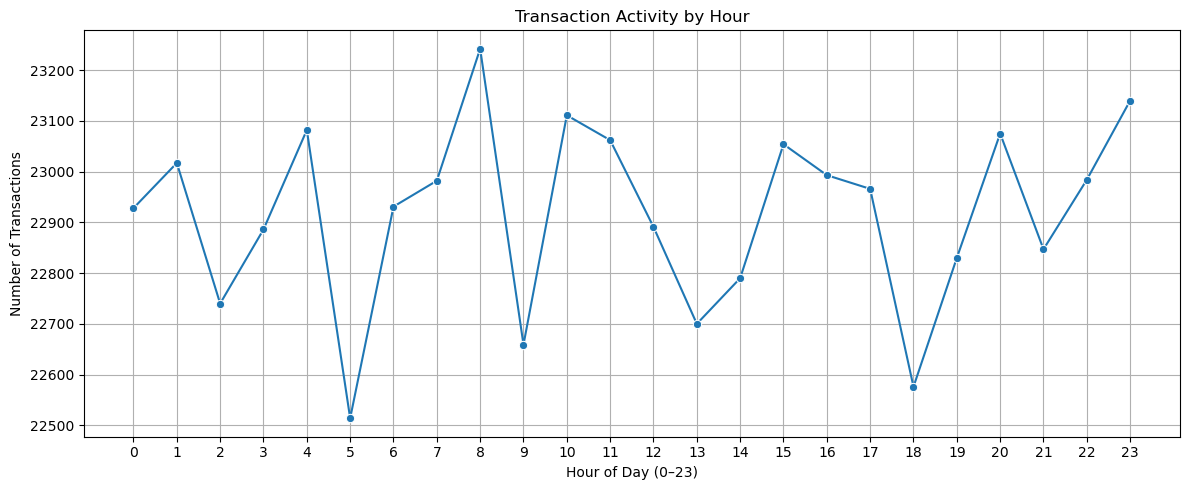

In [626]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hour_analysis,
    x="transaction_hour",
    y="total_transactions",
    marker="o"
)

plt.title("Transaction Activity by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Number of Transactions")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
## week

In [636]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

df["day_of_week"] = df["transaction_date"].dt.day_name()

day_analysis = df.groupby("day_of_week").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum")
).reset_index()

day_analysis["percentage"]=(day_analysis["total_amount"]/total_value*100)

day_analysis.sort_values(by="percentage",ascending=False)


,day_of_week,total_transactions,total_amount,percentage
5,Tuesday,78420,2408052258.52,14.64
3,Sunday,78630,2399534857.42,14.59
2,Saturday,78764,2385856219.79,14.50
0,Friday,78821,2340865862.81,14.23
1,Monday,78528,2320520791.04,14.11
4,Thursday,78256,2316617484.42,14.08
6,Wednesday,78581,2277454189.56,13.85


In [648]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

df["day_of_week"] = df["transaction_date"].dt.day_name()

day_analysis = df.groupby("day_of_week").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum")
).reset_index()

day_analysis["percentage"]=(day_analysis["total_transactions"]/total_transactions*100)

day_analysis.sort_values(by="percentage",ascending=False)

,day_of_week,total_transactions,total_amount,percentage
0,Friday,78821,2340865862.81,14.33
2,Saturday,78764,2385856219.79,14.32
3,Sunday,78630,2399534857.42,14.30
6,Wednesday,78581,2277454189.56,14.29
1,Monday,78528,2320520791.04,14.28
5,Tuesday,78420,2408052258.52,14.26
4,Thursday,78256,2316617484.42,14.23


In [ ]:
# month

In [656]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

df["month"] = df["transaction_date"].dt.month_name()

month_analysis = df.groupby("month").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum")
).reset_index()

month_analysis ["percentage"]=(month_analysis ["total_amount"]/total_value*100)

month_analysis .sort_values(by="percentage",ascending=False)


,month,total_transactions,total_amount,percentage
8,May,46721,1434671656.09,8.72
5,July,46921,1423234900.13,8.65
2,December,46434,1419690021.70,8.63
1,August,47003,1396784933.45,8.49
7,March,46332,1391179312.09,8.46
10,October,46826,1387306298.94,8.43
4,January,47167,1349048258.11,8.20
0,April,44829,1341992674.71,8.16
6,June,45416,1341438507.34,8.16
9,November,45253,1335715660.27,8.12


In [663]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

df["year"] = df["transaction_date"].dt.year

year_analysis = df.groupby("year").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum")
).reset_index()

year_analysis["percentage"]=(year_analysis ["total_amount"]/total_value*100)

year_analysis .sort_values(by="percentage",ascending=False)

,year,total_transactions,total_amount,percentage
3,2022,110247,3344988460.30,20.34
1,2020,109767,3315647465.35,20.16
4,2023,109584,3265949139.69,19.86
0,2019,110083,3258465232.49,19.81
2,2021,110024,3253234935.54,19.78
5,2024,295,10616430.19,0.06


In [667]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

df["year"] = df["transaction_date"].dt.year

year_analysis = df.groupby("year").agg(
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum")
).reset_index()

year_analysis["percentage"]=(year_analysis ["total_transactions"]/total_transactions*100)

year_analysis .sort_values(by="percentage",ascending=False)

,year,total_transactions,total_amount,percentage
3,2022,110247,3344988460.30,20.04
0,2019,110083,3258465232.49,20.02
2,2021,110024,3253234935.54,20.00
1,2020,109767,3315647465.35,19.96
4,2023,109584,3265949139.69,19.92
5,2024,295,10616430.19,0.05


In [665]:
df["transaction_date"].describe()

count                           550000
mean     2021-07-01 23:27:05.995636480
min                2019-01-01 00:00:00
25%                2020-04-01 00:00:00
50%                2021-07-03 00:00:00
75%                2022-10-01 00:00:00
max                2024-01-01 00:00:00
Name: transaction_date, dtype: object

In [681]:
df.columns

Index(['transaction_id', 'customer_id', 'transaction_date', 'transaction_time',
       'account_type', 'transaction_type', 'transaction_amount',
       'transaction_direction', 'account_balance', 'merchant_category',
       'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount',
       'transaction_status', 'channel', 'kyc_status', 'is_fraud',
       'transaction_hour', 'data_quality_flag', 'day_of_week', 'month',
       'year'],
      dtype='object')

In [659]:
# state

In [689]:
state_analysis = df.groupby("state").agg(                       
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()



state_analysis["percentage"]=(state_analysis["total_amount"]/total_value*100)

state_analysis.sort_values(by="percentage",ascending=False)

,state,total_transactions,total_amount,average_amount,percentage
3,Maharashtra,98911,2980264901.72,30130.77,18.12
2,Karnataka,76659,2256631611.09,29437.27,13.72
6,Tamil Nadu,71747,2148851576.48,29950.40,13.06
0,Delhi,66114,1981774201.35,29975.11,12.05
1,Gujarat,54798,1682204920.36,30698.29,10.23
7,Telangana,49610,1426830259.24,28760.94,8.67
9,West Bengal,43950,1315250791.00,29926.07,8.00
5,Rajasthan,38725,1170165309.56,30217.31,7.11
8,UP,27414,839996022.23,30641.13,5.11
4,Punjab,22072,646932070.53,29310.08,3.93


In [686]:
df.head(1)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,...,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour,data_quality_flag,day_of_week,month,year
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,...,0.00,Success,Branch,Verified,0,15,Valid,Tuesday,January,2019


## Merchant_category & emi_amount ##

In [691]:
merchant_cat_analysis = df.groupby("merchant_category").agg(                       
    total_transactions=("transaction_amount", "count"),
    total_amount=("transaction_amount", "sum"),
    average_amount=("transaction_amount", "mean")
).reset_index()



merchant_cat_analysis["percentage"]=(merchant_cat_analysis["total_amount"]/total_value*100)

merchant_cat_analysis.sort_values(by="percentage",ascending=False)

,merchant_category,total_transactions,total_amount,average_amount,percentage
11,Retail,66180,2004894940.56,30294.57,12.19
3,Food & Dining,54776,1650395103.08,30129.89,10.03
0,E-Commerce,54767,1618020617.77,29543.71,9.84
12,Salary,43937,1332665439.50,30331.28,8.10
13,Travel,44177,1308024963.50,29608.73,7.95
9,Peer Transfer,38753,1156194791.33,29834.98,7.03
14,Utilities,38575,1127987302.84,29241.41,6.86
6,Healthcare,33015,975250487.83,29539.62,5.93
2,Entertainment,32997,974529338.27,29533.88,5.92
8,Investment,27380,847424695.65,30950.50,5.15


In [694]:
df["emi_amount"].describe()

count   550000.00
mean      2365.86
std       4973.55
min          0.00
25%          0.00
50%          0.00
75%       3115.03
max     153325.74
Name: emi_amount, dtype: float64

In [712]:
df.to_csv("Banking_transaction_final_data.csv", index=False)